# 03 · Paired differential expression
Paired t-test on within-patient log2 differences, Benjamini–Hochberg FDR; Wilcoxon signed-rank as a sensitivity check.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
from oncogene.config import Paths, load_config
from oncogene.data.load import load_processed
paths, cfg = Paths(), load_config()
ds = load_processed(paths)
X, meta, ann = ds.X, ds.meta, ds.annotation
M = paths.metrics
print(X.shape, meta.shape)

(50, 17868) (50, 9)


In [2]:
de = pd.read_csv(M/'de_results.csv', index_col='probe_id', dtype={'probe_id': str})
de.head(15)[['gene_symbol','log2_fold_change','cohens_dz','p_adj','wilcoxon_p_adj','significant']]

,gene_symbol,log2_fold_change,cohens_dz,p_adj,wilcoxon_p_adj,significant
probe_id,,,,,,
4004044,DMD,-2.6860,-4.501114,2.162499e-13,0.000293,True
4000538,FIGF,-4.1400,-4.025461,1.385482e-12,0.000293,True
3830189,FXYD1,-1.8416,-3.773744,3.981550e-12,0.000293,True
3745525,TMEM220,-1.0784,-3.401752,3.027467e-11,0.000293,True
2701109,IGSF10,-2.4704,-3.368880,3.027467e-11,0.000293,True
3062082,PDK4,-2.9824,-3.285850,4.231668e-11,0.000293,True
2591421,TFPI,-2.2128,-3.268299,4.231668e-11,0.000293,True
3768627,ABCA8,-3.0868,-3.225939,4.938329e-11,0.000293,True
3863576,PAFAH1B3,1.3412,3.163706,6.740272e-11,0.000293,True


In [3]:
sig = de[de.significant]
print(f"FDR<0.05: {(de.p_adj<0.05).sum()}, +|log2FC|>=1: {len(sig)} (up {(sig.log2_fold_change>0).sum()}, down {(sig.log2_fold_change<0).sum()})")
print('Agreement t-test vs Wilcoxon at FDR<0.05:', ((de.p_adj<0.05)==(de.wilcoxon_p_adj<0.05)).mean().round(3))

FDR<0.05: 8220, +|log2FC|>=1: 830 (up 365, down 465)
Agreement t-test vs Wilcoxon at FDR<0.05: 0.968


Text(0, 0.5, '-log10 FDR')

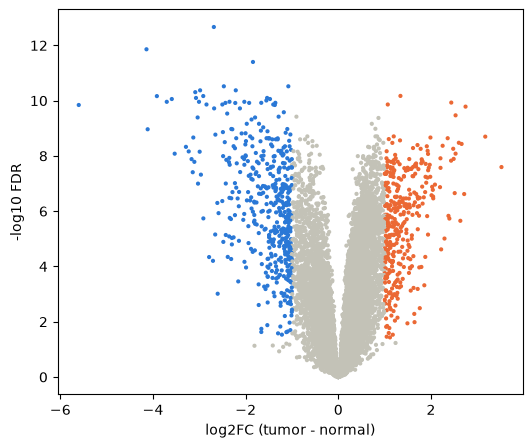

In [4]:
fig, ax = plt.subplots(figsize=(6,5))
c = np.where(~de.significant, '#c3c2b7', np.where(de.log2_fold_change>0, '#eb6834', '#2a78d6'))
ax.scatter(de.log2_fold_change, de.neg_log10_p_adj, c=c, s=4); ax.set_xlabel('log2FC (tumor - normal)'); ax.set_ylabel('-log10 FDR')

In [5]:
sig.nlargest(15,'log2_fold_change')[['gene_symbol','gene_description','log2_fold_change','p_adj']]

,gene_symbol,gene_description,log2_fold_change,p_adj
probe_id,,,,
3901361,CST1,cystatin SN,3.5220,2.530465e-08
3939470,MMP11,matrix metallopeptidase 11 (stromelysin 3),3.1720,2.004297e-09
3444043,OLR1,oxidized low density lipoprotein (lectin-like)...,2.7464,1.645016e-10
2773958,CXCL10,chemokine (C-X-C motif) ligand 10,2.7172,2.395044e-07
3756193,TOP2A,topoisomerase (DNA) II alpha 170kDa,2.6616,3.685081e-09
2773947,CXCL9,chemokine (C-X-C motif) ligand 9,2.6340,2.225739e-06
3178583,CKS2,CDC28 protein kinase regulatory subunit 2,2.6016,3.347040e-09
3881443,TPX2,"TPX2, microtubule-associated, homolog (Xenopus...",2.5312,3.401491e-10
3629103,KIAA0101,KIAA0101,2.5312,8.276968e-09


In [6]:
sig.nsmallest(15,'log2_fold_change')[['gene_symbol','gene_description','log2_fold_change','p_adj']]

,gene_symbol,gene_description,log2_fold_change,p_adj
probe_id,,,,
3142381,FABP4,"fatty acid binding protein 4, adipocyte",-5.6016,1.435279e-10
4000538,FIGF,c-fos induced growth factor (vascular endothel...,-4.1400,1.385482e-12
2656818,ADIPOQ,"adiponectin, C1Q and collagen domain containing",-4.1144,1.085823e-09
4018080,CHRDL1,chordin-like 1,-3.9156,6.853812e-11
2779231,ADH1B,"alcohol dehydrogenase 1B (class I), beta polyp...",-3.7020,1.101341e-10
3362826,LYVE1,lymphatic vessel endothelial hyaluronan recept...,-3.5936,8.734584e-11
3010503,CD36,CD36 molecule (thrombospondin receptor),-3.5312,8.301575e-09
3391149,FDXACB1,ferredoxin-fold anticodon binding domain conta...,-3.2884,4.696128e-09
3274758,AKR1C2,"aldo-keto reductase family 1, member C2 (dihyd...",-3.2284,6.873227e-09


## P-value distribution
A strong spike near 0 with a flat remainder indicates abundant true signal and well-behaved tests.

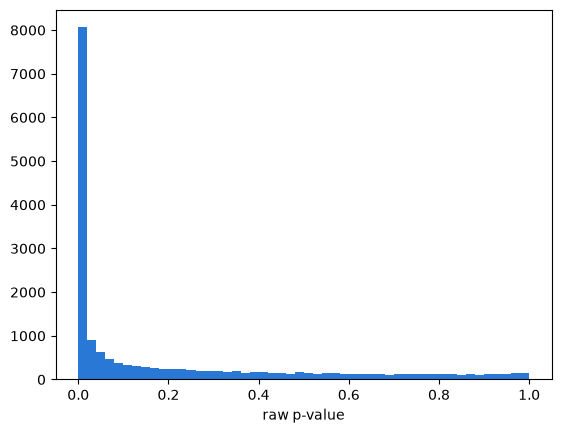

In [7]:
plt.hist(de.p_value, bins=50, color='#2a78d6'); plt.xlabel('raw p-value');